# Monte Carlo Methods in Finance: a short demo

A quick tour of the `mcfinance` library in four steps. Each step uses a fixed seed and runs in seconds; the whole notebook runs in well under 2 minutes and needs no network access.

1. Price a European call by Monte Carlo and check it against Black-Scholes.
2. Reduce the variance at equal budget: plain vs control variate vs combined.
3. Price an arithmetic Asian call, which has no closed form, with the geometric control variate.
4. Compute the 1-day 99% VaR and Expected Shortfall of an equity portfolio.

The full studies, with more paths, tables and discussion, are in [`docs/`](../docs) and are reproduced by the scripts in [`scripts/`](../scripts).

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Make the package importable without installing it (works from notebooks/ or the repo root).
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import mcfinance as mc

plt.rcParams.update({"figure.dpi": 90, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#dddddd", "axes.titleweight": "bold",
                     "axes.titlelocation": "left", "legend.frameon": False})
BLUE, ORANGE = "#2a78d6", "#eb6834"
S0, K, R, SIGMA, T = 100.0, 100.0, 0.05, 0.2, 1.0

## 1. European call: Monte Carlo vs Black-Scholes

Under the risk-neutral measure, $S_T = S_0\exp\big((r - \tfrac{1}{2}\sigma^2)T + \sigma\sqrt{T}Z\big)$ can be sampled exactly. The price is the discounted mean payoff, and the central limit theorem gives a standard error $s/\sqrt{n}$ and a 95% confidence interval. The figure follows the running estimate along one long sample: the interval shrinks like $1/\sqrt{n}$ and keeps covering the exact price.

Monte Carlo : 10.4634 +/- 0.0331 (95% CI [10.3985, 10.5283], n=200,000)
Black-Scholes: 10.4506  -> inside the 95% CI: True


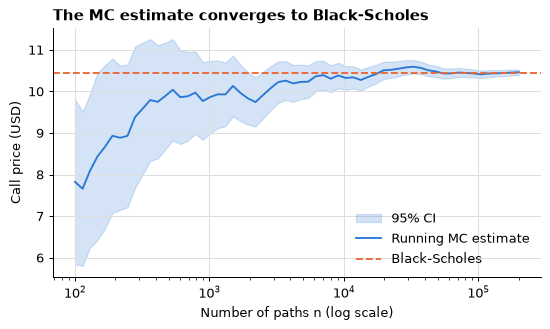

In [2]:
exact = mc.bs_price(S0, K, R, SIGMA, T, "call")
res = mc.price_european(S0, K, R, SIGMA, T, n=200_000, rng=42)
print(f"Monte Carlo : {res}")
print(f"Black-Scholes: {exact:.4f}  -> inside the 95% CI: {res.contains(exact)}")

ns, prices, ses = mc.convergence_curve(S0, K, R, SIGMA, T, n_max=200_000, rng=42)
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.fill_between(ns, prices - 1.96 * ses, prices + 1.96 * ses, color=BLUE, alpha=0.2, label="95% CI")
ax.plot(ns, prices, color=BLUE, label="Running MC estimate")
ax.axhline(exact, color=ORANGE, linestyle="--", label="Black-Scholes")
ax.set_xscale("log")
ax.set_xlabel("Number of paths n (log scale)")
ax.set_ylabel("Call price (USD)")
ax.set_title("The MC estimate converges to Black-Scholes")
ax.legend()
plt.show()

## 2. Variance reduction at equal budget

With the same number of payoff evaluations $n = 20{,}000$, we compare plain Monte Carlo with two variance reduction methods. The first is a control variate, the discounted terminal price $e^{-rT}S_T$, whose mean $S_0$ is known exactly. The second combines that control variate with antithetic variates ($Z$ and $-Z$). The variance of each estimator is measured from 200 independent runs, not taken from its own reported standard error.

In [3]:
params = dict(S0=S0, K=K, r=R, sigma=SIGMA, T=T, n=20_000)
rng = np.random.default_rng(42)
methods = {
    "Plain MC": mc.price_european,
    "Control variate": mc.price_european_control_variate,
    "Antithetic + control variate": mc.price_european_combined,
}
variances = {name: mc.estimator_variance(f, 200, rng=rng, **params) for name, f in methods.items()}
table = pd.DataFrame({
    "Std of the price over 200 runs": {k: np.sqrt(v) for k, v in variances.items()},
    "Variance reduction factor": {k: variances["Plain MC"] / v for k, v in variances.items()},
})
table.round(4)

,Std of the price over 200 runs,Variance reduction factor
Plain MC,0.0992,1.0000
Control variate,0.0412,5.7871
Antithetic + control variate,0.0180,30.3254


## 3. Arithmetic Asian call with the geometric control variate

The arithmetic Asian call pays $(A - K)^+$, where $A$ is the average price over $m = 52$ weekly dates. A sum of lognormals has no closed-form law, so Monte Carlo is needed. The *geometric* average $G$ is lognormal and has an exact price, and on every path $A$ and $G$ are extremely close. Using the geometric payoff as a control variate therefore removes almost all of the noise.

In [4]:
m, n = 52, 20_000
plain = mc.price_asian(S0, K, R, SIGMA, T, n, m, rng=42)
cv = mc.price_asian(S0, K, R, SIGMA, T, n, m, control_variate=True, rng=42)
print(f"Plain MC        : {plain}")
print(f"Control variate : {cv}")
print(f"Correlation arithmetic / geometric payoff: rho = {cv.rho:.5f}")
print(f"Standard error divided by {plain.std_error / cv.std_error:.1f} "
      f"(variance by about {(plain.std_error / cv.std_error) ** 2:.0f}) at the same n")
print(f"Geometric Asian closed form (the control's exact mean): "
      f"{mc.geometric_asian_price(S0, K, R, SIGMA, T, m):.4f}")

Plain MC        : 5.7918 +/- 0.0567 (95% CI [5.6806, 5.9030], n=20,000)
Control variate : 5.8524 +/- 0.0015 (95% CI [5.8493, 5.8554], n=20,000)
Correlation arithmetic / geometric payoff: rho = 0.99963
Standard error divided by 36.9 (variance by about 1364) at the same n
Geometric Asian closed form (the control's exact mean): 5.6374


## 4. 1-day 99% VaR and Expected Shortfall of an equity portfolio

Losses are positive numbers, for an equally weighted portfolio worth 1,000,000 EUR, estimated from the last 500 daily returns. VaR is the 99% quantile of the loss; ES is the average loss beyond it. We compare a normal model (Cholesky Monte Carlo), a Student-t model with the same covariance, and historical simulation.

**Data.** The cell uses `data/prices.csv` (five CAC 40 stocks from Yahoo Finance, created by `python scripts/download_data.py`) if it exists. **If it does not, the cell falls back to a clearly labelled synthetic dataset** (correlated normal returns with a fixed seed) and prints a notice. No network access is needed either way. The printed line below shows which source was used for the stored output.

Data source: data/prices.csv (Yahoo Finance), 2024-11-04 to 2026-10-20
                       VaR 99%   ES 99%
MC normal              23611.0  27035.0
MC Student-t (nu=5)    26147.0  34234.0
Historical simulation  28154.0  43331.0


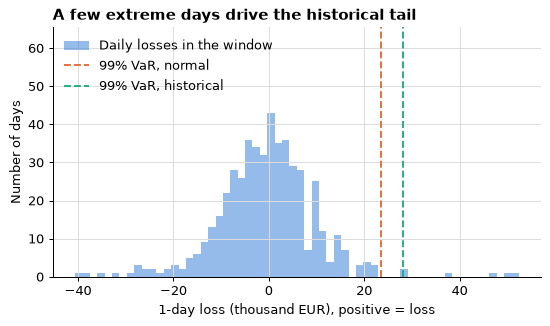

In [5]:
V, LEVEL = 1_000_000.0, 0.99
data_file = ROOT / "data" / "prices.csv"
if data_file.exists():
    prices = pd.read_csv(data_file, index_col="Date", parse_dates=True)
    returns = np.log(prices).diff().dropna().iloc[-500:]
    print(f"Data source: {data_file.relative_to(ROOT)} (Yahoo Finance), "
          f"{returns.index[0].date()} to {returns.index[-1].date()}")
else:
    vols = np.array([0.017, 0.016, 0.014, 0.019, 0.020])
    corr = np.full((5, 5), 0.45) + 0.55 * np.eye(5)
    synthetic = mc.cholesky_correlated_normals(np.outer(vols, vols) * corr, 500, rng=42)
    returns = pd.DataFrame(synthetic, columns=[f"Asset {i + 1}" for i in range(5)])
    print("NOTICE: data/prices.csv not found -> SYNTHETIC multivariate-normal returns, not market data")

r = returns.to_numpy()
w = np.full(r.shape[1], 1 / r.shape[1])
results = {
    "MC normal": mc.estimate_risk("mc_normal", r, w, V, (LEVEL,), n_sims=200_000, rng=42),
    "MC Student-t (nu=5)": mc.estimate_risk("mc_student_t", r, w, V, (LEVEL,), n_sims=200_000, rng=42),
    "Historical simulation": mc.estimate_risk("historical", r, w, V, (LEVEL,)),
}
print(pd.DataFrame({name: {"VaR 99%": res.var[LEVEL], "ES 99%": res.es[LEVEL]}
                    for name, res in results.items()}).T.round(0))

losses = mc.portfolio_losses(r, w, V) / 1e3
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.hist(losses, bins=60, color=BLUE, alpha=0.5, label="Daily losses in the window")
ax.axvline(results["MC normal"].var[LEVEL] / 1e3, color=ORANGE, linestyle="--", label="99% VaR, normal")
ax.axvline(results["Historical simulation"].var[LEVEL] / 1e3, color="#1baf7a", linestyle="--",
           label="99% VaR, historical")
ax.set_xlabel("1-day loss (thousand EUR), positive = loss")
ax.set_ylabel("Number of days")
ax.set_title("A few extreme days drive the historical tail")
ax.set_ylim(top=ax.get_ylim()[1] * 1.45)  # headroom for the legend
ax.legend(loc="upper left")
plt.show()

The normal model typically understates the tail: the Student-t and historical ES are higher. The full study ([docs/part4_var_es.md](../docs/part4_var_es.md)) backtests these models over 3,285 days. No model passes the 99% backtest, mainly because exceptions cluster in volatile periods.